# Lista 8: O Jev, decisão calibrada
**Caderno de atividades do Capítulo 8** | **A ginga dos números**, livro de exercícios | Professor Bruno Menezes | [repositório](https://github.com/brunoleomenezes/ginga-dos-numeros)

Nome: ______________________  Turma: ______________

O código de cada exercício já está nas células, com a saída visível, para você conferir. O ideal é **digitar** o código em um caderno seu, como pede a Lista em PDF, e usar este caderno para comparar. Execute as células **na ordem**: quase todas dependem das anteriores. Em caso de dúvida, use *Ambiente de execução > Reiniciar sessão e executar tudo*.

## Parte 1. Seis ferramentas novas de Python

### B1. Dicionários de probabilidades: escolher a maior

Um modelo de decisão devolve uma probabilidade para cada opção. Em Python, isso cabe em um **dicionário**. A função **max** com o argumento **key** devolve a chave de maior valor, e **sum** soma os valores.

In [1]:
# Cria um dicionário (pares chave: valor entre chaves): cada opção recebe a sua probabilidade
probs = {"cobrança": 0.90, "técnico": 0.07, "comercial": 0.03}

# max com key=probs.get compara os valores (probabilidades) e devolve a chave do maior deles
escolha = max(probs, key=probs.get)
# print mostra na tela o texto e o valor guardado na variável escolha
print("escolha:", escolha)
# probs[escolha] busca no dicionário o valor da chave escolhida (a probabilidade dela)
print("probabilidade:", probs[escolha])
# .values() pega só as probabilidades, sum as soma e round arredonda para 4 casas (deve dar 1)
print("soma das probabilidades:", round(sum(probs.values()), 4))

# Laço for: .items() entrega cada par (opção, probabilidade), um de cada vez
for opcao, p in probs.items():
    # f-string: {opcao:10s} ocupa 10 espaços e {p * 100:5.1f} mostra o percentual com 1 casa
    print(f"{opcao:10s} {p * 100:5.1f}%")

escolha: cobrança
probabilidade: 0.9
soma das probabilidades: 1.0
cobrança    90.0%
técnico      7.0%
comercial    3.0%


O **key=probs.get** manda o max comparar os valores, e não os nomes. A soma de uma distribuição de probabilidade é sempre 1.

**SUA VEZ**

1. Troque a probabilidade de técnico para 0.50 e ajuste as outras para que a soma continue 1. Qual é a nova escolha?
2. Calcule 1 menos a probabilidade da escolha. O que esse número representa?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [2]:
# Espaço para os seus testes

### B2. Números aleatórios com semente

Os exemplos de calibração usam dados **sintéticos**, sorteados pelo computador. Para o sorteio dar sempre o mesmo resultado, usa-se uma **semente**: **np.random.default_rng(8)** cria um gerador com a semente 8. O método **uniform** sorteia números em um intervalo, e comparar o sorteio com uma probabilidade simula um acerto ou erro.

In [3]:
# import traz a biblioteca NumPy (contas com vetores) e a apelida de np
import numpy as np

# Cria um gerador de números aleatórios com a semente 8, para o sorteio sair sempre igual
rng = np.random.default_rng(8)
# O método uniform sorteia 5 números entre 0.5 e 0.95: serão as probabilidades declaradas
p = rng.uniform(0.5, 0.95, 5)
# .round(4) arredonda cada número do vetor para 4 casas antes de mostrar
print("probabilidades:", p.round(4))

# Sorteia mais 5 números entre 0 e 1 (o intervalo padrão do uniform)
sorteio = rng.uniform(size=5)
# sorteio < p dá verdadeiro com chance p; .astype(int) troca verdadeiro por 1 e falso por 0
acertou = (sorteio < p).astype(int)
# Mostra os números sorteados, arredondados
print("sorteio       :", sorteio.round(4))
# Mostra 1 para acerto e 0 para erro em cada um dos 5 casos simulados
print("acertou       :", acertou)

# Um segundo gerador com a mesma semente 8 começa a sequência do zero
rng2 = np.random.default_rng(8)
# np.allclose confere se dois vetores são iguais (a menos de arredondamento): deve dar True
print("mesma semente, mesmos números:", np.allclose(rng2.uniform(0.5, 0.95, 5), p))

probabilidades: [0.6471 0.9443 0.6434 0.8548 0.8915]
sorteio       : [0.3911 0.4379 0.3727 0.107  0.479 ]
acertou       : [1 1 1 1 1]
mesma semente, mesmos números: True


Quem usar a mesma semente obtém exatamente os mesmos números, e é por isso que a sua saída deve coincidir com a do livro. O teste **sorteio &lt; p** dá verdadeiro com probabilidade p.

**SUA VEZ**

1. Troque a semente para 9. O que muda nas probabilidades?
2. Sorteie 1000 números e conte quantos são menores que 0.7. O resultado fica perto de quê?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [4]:
# Espaço para os seus testes

### B3. Máscaras booleanas: escolher por faixa

Para montar a tabela de confiabilidade é preciso separar as previsões por faixa de probabilidade. Em NumPy, uma **máscara booleana** é um vetor de verdadeiro e falso, e **p[mascara]** guarda só os elementos em que a máscara é verdadeira. O **&amp;** combina duas condições.

In [5]:
# Importa o NumPy de novo, para a célula funcionar sozinha
import numpy as np

# np.array transforma a lista de probabilidades declaradas em um vetor do NumPy
p = np.array([0.52, 0.58, 0.64, 0.71, 0.83, 0.91, 0.95])
# Vetor de acertos: 1 se a previsão estava certa, 0 se estava errada
acertou = np.array([1, 0, 1, 1, 1, 1, 0])

# Máscara booleana: verdadeiro onde p está na faixa de 0.6 até 0.9; o & exige as duas condições
mascara = (p >= 0.6) & (p < 0.9)
# Mostra o vetor de verdadeiros e falsos
print("máscara:", mascara)
# p[mascara] guarda só os elementos em que a máscara é verdadeira
print("p na faixa:", p[mascara])
# Somar a máscara conta os verdadeiros (cada verdadeiro vale 1); int deixa o número inteiro
print("quantos:", int(mascara.sum()))
# .mean() calcula a média: a confiança média declarada nessa faixa
print("confiança média:", round(p[mascara].mean(), 4))
# A média de zeros e uns é a proporção de acertos na faixa (o acerto observado)
print("acerto observado:", round(acertou[mascara].mean(), 4))

máscara: [False False  True  True  True False False]
p na faixa: [0.64 0.71 0.83]
quantos: 3
confiança média: 0.7267
acerto observado: 1.0


A média de um vetor de zeros e uns é a proporção de uns. Por isso **acertou[mascara].mean()** é a frequência de acerto na faixa.

**SUA VEZ**

1. Crie a máscara da faixa 0.9 a 1.0 e calcule a confiança média e o acerto observado.
2. Quantas previsões têm p menor que 0.6?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [6]:
# Espaço para os seus testes

### B4. Funções que devolvem mais de um valor

Uma função pode devolver vários valores de uma vez, separados por vírgula (uma **tupla**), e quem chama pode guardá-los em variáveis separadas. Os argumentos podem ter um **valor padrão**, usado quando o argumento não é passado.

In [7]:
# def cria uma função; n=3 é um valor padrão, usado quando quem chama não informa o n
def confianca_choice(pmax, n=3):
    # Reescala a probabilidade: 1/n (chute ao acaso) vira 0 e 1 (certeza total) vira 1
    conf = (pmax - 1 / n) / (1 - 1 / n)
    # return devolve dois valores de uma vez (uma tupla): a confiança e a chance de erro
    return conf, 1 - pmax

# Chama a função sem n (vale o padrão 3) e guarda os dois resultados em duas variáveis
c, erro = confianca_choice(0.90)
# Mostra a confiança e o erro, arredondados para 4 casas
print("n = 3 (padrão):", round(c, 4), round(erro, 4))

# Agora com n=2; o sublinhado _ recebe o segundo valor, que não vamos usar
c2, _ = confianca_choice(0.90, n=2)
# Mostra a confiança para duas opções
print("n = 2         :", round(c2, 4))

n = 3 (padrão): 0.85 0.1
n = 2         : 0.8


Com n = 3 e probabilidade 0.90 a confiança é 0.85, e com n = 2 é 0.80. O sublinhado **_** é o costume para um valor que não vamos usar.

**SUA VEZ**

1. Calcule a confiança para pmax = 0.7 com n = 4.
2. Escreva uma função que receba uma lista de probabilidades e devolva a escolha e a confiança.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [8]:
# Espaço para os seus testes

### B5. Achar o melhor número: minimize_scalar

O escalonamento de temperatura procura o T que dá a menor perda. A função **minimize_scalar**, do SciPy, encontra o valor de um número que minimiza uma função, dentro de limites. É a mesma ideia da descida do gradiente do Capítulo 3, mas para um número só.

In [9]:
# from ... import traz só a função minimize_scalar do módulo de otimização do SciPy
from scipy.optimize import minimize_scalar

# Função de teste: uma parábola cujo menor valor (0.5) acontece em t = 2.3
def perda(t):
    # Devolve a perda para o valor t; ** 2 é elevar ao quadrado
    return (t - 2.3) ** 2 + 0.5

# Procura o t de menor perda entre 0.5 e 5.0 (bounds); o método "bounded" respeita esses limites
r = minimize_scalar(perda, bounds=(0.5, 5.0), method="bounded")
# r.x é o valor de t encontrado
print("t que minimiza:", round(r.x, 4))
# r.fun é o valor da perda nesse ponto (o mínimo)
print("valor mínimo  :", round(r.fun, 4))

t que minimiza: 2.3
valor mínimo  : 0.5


A função de teste tem o mínimo em 2.3, e o SciPy o encontra sem derivadas nem passos escritos por você.

**SUA VEZ**

1. Mude o 2.3 para 1.7 e rode de novo.
2. Procure o mesmo mínimo com um laço que testa t de 0.5 a 5.0, de 0.01 em 0.01. Os resultados coincidem?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [10]:
# Espaço para os seus testes

### B6. Gráfico de confiabilidade

A tabela de confiabilidade é um gráfico em que o eixo horizontal é a probabilidade declarada e o vertical é o acerto observado. A **diagonal** é a calibração perfeita. Os pontos abaixo dela mostram um modelo confiante demais.

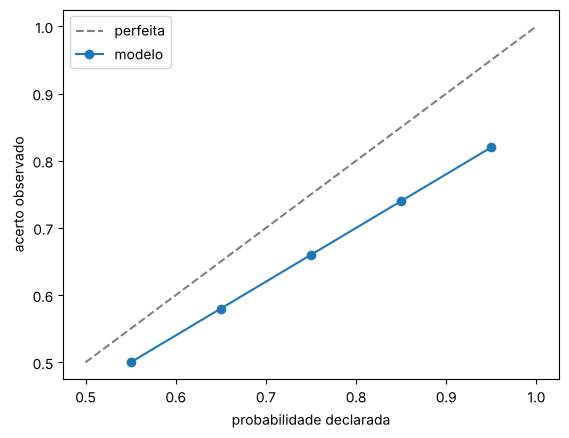

In [11]:
# Importa o NumPy para criar os vetores
import numpy as np
# Importa o módulo de gráficos do Matplotlib, apelidado de plt
import matplotlib.pyplot as plt

# Probabilidades declaradas pelo modelo em cada faixa (eixo horizontal)
declarada = np.array([0.55, 0.65, 0.75, 0.85, 0.95])
# Acerto observado em cada faixa (eixo vertical): sempre menor que o declarado
observada = np.array([0.50, 0.58, 0.66, 0.74, 0.82])

# Desenha a diagonal tracejada cinza de (0.5, 0.5) a (1, 1): a calibração perfeita
plt.plot([0.5, 1], [0.5, 1], linestyle="--", color="gray", label="perfeita")
# Desenha a curva do modelo, com uma bolinha em cada ponto
plt.plot(declarada, observada, marker="o", label="modelo")
# Dá nome ao eixo horizontal
plt.xlabel("probabilidade declarada")
# Dá nome ao eixo vertical
plt.ylabel("acerto observado")
# Mostra a legenda com os nomes dados em label
plt.legend()
# Exibe o gráfico na tela
plt.show()

Os pontos do modelo ficam abaixo da diagonal em todas as faixas: ele declara mais certeza do que acerta.

**SUA VEZ**

1. Acrescente uma segunda curva, calibrada, com observada igual a declarada.
2. Como ficaria o gráfico de um modelo que fosse tímido demais?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [12]:
# Espaço para os seus testes

## Parte 2. Os dez exercícios do capítulo

### Exercício 1. O softmax restrito: três opções, uma resposta válida
*Exemplo 1 do capítulo*

Vamos aplicar o softmax às seis palavras (livre) e só às três opções permitidas (restrito), e calcular a confiança oficial. As pontuações são ilustrativas.

In [13]:
# Importa o NumPy
import numpy as np

# Lista com as seis palavras que o modelo poderia escrever
palavras = ["cobrança", "técnico", "comercial", "reembolso", "desculpe", "ticket"]
# Pontuações (logits) de cada palavra, na mesma ordem da lista (valores ilustrativos)
z = np.array([2.4, 0.2, 0.5, 3.0, 1.6, 0.9])
# Posições das três opções permitidas: cobrança, técnico e comercial
dentro = [0, 1, 2]

# Função softmax: transforma pontuações em probabilidades que somam 1
def softmax(z):
    # np.exp aplica a exponencial a cada número; subtrair o maior evita números gigantes
    e = np.exp(z - z.max())
    # Divide pela soma para que as probabilidades fiquem entre 0 e 1 e somem 1
    return e / e.sum()

# Softmax livre: sobre as seis palavras
livre = softmax(z)
# Softmax restrito: z[dentro] pega só as pontuações das três opções permitidas
restrito = softmax(z[dentro])
# enumerate entrega a posição i e a palavra pal a cada volta do laço
for i, pal in enumerate(palavras):
    # Expressão condicional (if ... else em uma linha): se a palavra é opção, mostra o percentual
    # restrito (dentro.index(i) acha a posição dela em dentro); senão, mostra um traço
    r = f"{restrito[dentro.index(i)] * 100:6.2f}%" if i in dentro else "     -"
    # Mostra a linha da tabela: palavra, pontuação, percentual livre e percentual restrito
    print(f"{pal:10s} pontuação {z[i]:3.1f}  livre {livre[i] * 100:6.2f}%  restrita {r}")

# print vazio pula uma linha
print()
# np.argmax dá a posição do maior valor; com ela buscamos a palavra mais provável sem restrição
print("mais provável (livre):", palavras[int(np.argmax(livre))])
# argmax dá a posição dentro das opções; dentro[...] converte para a posição na lista de palavras
print("escolha restrita     :", palavras[dentro[int(np.argmax(restrito))]])
# Soma da probabilidade livre que caiu nas três opções permitidas (a massa dentro da lista)
print("massa dentro da lista:", round(livre[dentro].sum(), 4))

# Confiança oficial: reescala pmax para que o chute ao acaso (1/n) valha 0
def confianca(pmax, n):
    # Mesma fórmula da seção B4
    return (pmax - 1 / n) / (1 - 1 / n)

# Confiança da escolha restrita, com 3 opções
print("confiança oficial    :", round(confianca(restrito.max(), 3), 4))
# Confere o exemplo do artigo: probabilidade 0.90 com 3 opções dá 0.85
print("exemplo do artigo    :", round(confianca(0.90, 3), 4))

cobrança   pontuação 2.4  livre  26.63%  restrita  79.34%
técnico    pontuação 0.2  livre   2.95%  restrita   8.79%
comercial  pontuação 0.5  livre   3.98%  restrita  11.87%
reembolso  pontuação 3.0  livre  48.53%  restrita      -
desculpe   pontuação 1.6  livre  11.97%  restrita      -
ticket     pontuação 0.9  livre   5.94%  restrita      -

mais provável (livre): reembolso
escolha restrita     : cobrança
massa dentro da lista: 0.3357
confiança oficial    : 0.6901
exemplo do artigo    : 0.85


Livre, a palavra mais provável é reembolso (48,53%), que não é uma opção. Restrito, a escolha é cobrança com 79,34%, mas o modelo só dava 33,57% da probabilidade às três opções. A confiança oficial é 0,6901, e o exemplo do artigo dá 0,85.

**SUA VEZ**

1. Mude a pontuação de reembolso para 0.5. O que acontece com a massa dentro da lista?
2. Acrescente a opção financeiro com pontuação 0.1 à lista. Qual a nova escolha restrita?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [14]:
# Espaço para os seus testes

### Exercício 2. Score e Noul: média, confiança por dispersão e valor entre os níveis
*Exemplo 2 do capítulo*

Vamos calcular a nota (média ponderada) e a confiança de quatro distribuições sobre os níveis calmo, incomodado, irritado e furioso, e as confianças de uma Noul.

In [15]:
# Importa o NumPy
import numpy as np

# Os quatro níveis de irritação, do 0 (calmo) ao 3 (furioso)
niveis = ["calmo", "incomodado", "irritado", "furioso"]
# Dicionário com quatro distribuições de probabilidade sobre os níveis (o comando ocupa 4 linhas)
casos = {"espalhada":   [0.02, 0.08, 0.50, 0.40],
         "concentrada": [0.00, 0.05, 0.90, 0.05],
         "uniforme":    [0.25, 0.25, 0.25, 0.25],  # todos os níveis com a mesma chance
         "bimodal":     [0.45, 0.00, 0.00, 0.55]}  # dois picos, nos extremos

# Função que calcula a nota (Score) e a confiança por dispersão de uma distribuição
def score_conf(p):
    # Transforma a lista em vetor do NumPy
    p = np.array(p)
    # len conta quantos níveis existem
    n = len(p)
    # np.arange(n) cria o vetor 0, 1, 2, ..., n - 1 (o número de cada nível)
    i = np.arange(n)
    # Posição do nível mais provável
    m = int(np.argmax(p))
    # Dispersão de referência: distância média dos níveis ao centro da escala (np.abs tira o sinal)
    mad_u = np.mean(np.abs(i - (n - 1) / 2))
    # Dispersão: distância média, ponderada pela probabilidade, até o nível mais provável
    disp = float(np.sum(p * np.abs(i - m)))
    # Devolve a nota (média ponderada dos níveis), a confiança (cortada em 0 por max), a
    # dispersão e o nível mais provável
    return float(np.sum(i * p)), max(0.0, 1 - disp / mad_u), disp, m

# Percorre cada nome e distribuição do dicionário
for nome, p in casos.items():
    # Recebe os quatro resultados da função em quatro variáveis
    nota, conf, disp, m = score_conf(p)
    # Mostra o resumo do caso (o print continua na linha de baixo, dentro dos parênteses)
    print(f"{nome:12s} nota {nota:4.2f}  mais provável {niveis[m]:10s}",
          f"dispersão {disp:4.2f}  confiança {conf:4.2f}")

# Pula uma linha
print()
# Laço sobre uma tupla de três probabilidades da Noul (verdadeiro ou falso)
for p in (0.97, 0.50, 0.14):
    # |2p - 1| mede a distância até o meio (0.5): 0 é dúvida total e 1 é certeza
    print(f"Noul p = {p:4.2f}  |2p - 1| = {abs(2 * p - 1):4.2f}")

espalhada    nota 2.28  mais provável irritado   dispersão 0.52  confiança 0.48
concentrada  nota 2.00  mais provável irritado   dispersão 0.10  confiança 0.90
uniforme     nota 1.50  mais provável calmo      dispersão 1.50  confiança 0.00
bimodal      nota 1.65  mais provável furioso    dispersão 1.35  confiança 0.00

Noul p = 0.97  |2p - 1| = 0.94
Noul p = 0.50  |2p - 1| = 0.00
Noul p = 0.14  |2p - 1| = 0.72


A nota da distribuição espalhada é 2,28 e a confiança 0,48. Na uniforme a confiança é cortada em zero. Na bimodal a nota é 1,65, valor entre níveis a que o modelo deu probabilidade zero. Na Noul, 0,14 tem confiança 0,72 de que a afirmação é falsa.

**SUA VEZ**

1. Calcule à mão a nota e a confiança da distribuição [0.1, 0.2, 0.3, 0.4]. Confira com o código.
2. Invente uma distribuição com nota 1.5 e confiança alta. É possível? Explique.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [16]:
# Espaço para os seus testes

### Exercício 3. A tabela de confiabilidade e o ECE
*Exemplo 3 do capítulo*

Vamos gerar 500 previsões sintéticas, com semente fixa, para um modelo A calibrado e um modelo B confiante demais, e medir o ECE de cada um por faixas.

In [17]:
# Importa o NumPy
import numpy as np

# Gerador de números aleatórios com semente 8, para todos obterem os mesmos dados
rng = np.random.default_rng(8)
# Número de previsões sintéticas
N = 500
# Sorteia a chance real de acerto de cada caso, entre 0.5 e 0.95
p_true = rng.uniform(0.5, 0.95, N)
# Simula se cada resposta saiu certa (1) ou errada (0), com chance p_true
ok = (rng.uniform(size=N) < p_true).astype(int)

# Função logit: leva uma probabilidade de volta à pontuação (o inverso da sigmoide)
def logit(p):
    # np.log é o logaritmo natural, aplicado a cada número do vetor
    return np.log(p / (1 - p))

# Função sigmoide: transforma uma pontuação em probabilidade entre 0 e 1
def sigm(z):
    # Fórmula da sigmoide, aplicada a cada número
    return 1 / (1 + np.exp(-z))

# Modelo A: declara exatamente a chance real (calibrado); .copy() faz uma cópia independente
p_A = p_true.copy()
# Modelo B: multiplica a pontuação por 2.6, o que empurra as probabilidades para perto de 1
p_B = sigm(2.6 * logit(p_true))
# Limites das faixas; o último passa um pouco de 1 para incluir o valor 1.0 na última faixa
bins = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0000001]

# Monta a tabela de confiabilidade: uma linha por faixa
def tabela(p, ok):
    # Começa com uma lista vazia
    linhas = []
    # zip junta cada limite inferior (fatia bins[:-1]) ao superior (fatia bins[1:])
    for lo, hi in zip(bins[:-1], bins[1:]):
        # Máscara dos casos cuja probabilidade cai nesta faixa
        m = (p >= lo) & (p < hi)
        # .append acrescenta a linha: limites, quantidade, confiança média e acerto observado
        linhas.append((lo, hi, int(m.sum()), p[m].mean(), ok[m].mean()))
    # Devolve a lista de linhas
    return linhas

# ECE: média, ponderada pelo tamanho de cada faixa, da distância entre acerto e confiança
def ece(p, ok):
    # Expressão geradora dentro do sum: soma k/total * |acerto - confiança| de todas as faixas
    return sum(k / len(p) * abs(a - c) for lo, hi, k, c, a in tabela(p, ok))

# Proporção de acertos nos 500 casos (é a mesma para A e B, que escolhem a mesma resposta)
print("acerto global:", ok.mean())
# Título da tabela do modelo B
print("modelo B, faixa por faixa:")
# Percorre as linhas da tabela do modelo B, desempacotando os cinco valores
for lo, hi, k, c, a in tabela(p_B, ok):
    # Quanto esta faixa soma ao ECE
    contrib = k / N * abs(a - c)
    # Mostra a linha; min(hi, 1.0) exibe 1.0 no lugar de 1.0000001
    print(f"  {lo:.1f} a {min(hi, 1.0):.1f}  n={k:3d}  confiança {c:.3f}",
          f" acerto {a:.3f}  contribuição {contrib:.4f}")

acerto global: 0.748
modelo B, faixa por faixa:
  0.5 a 0.6  n= 43  confiança 0.558  acerto 0.419  contribuição 0.0120
  0.6 a 0.7  n= 39  confiança 0.654  acerto 0.641  contribuição 0.0010
  0.7 a 0.8  n= 56  confiança 0.752  acerto 0.679  contribuição 0.0082
  0.8 a 0.9  n= 83  confiança 0.855  acerto 0.735  contribuição 0.0199
  0.9 a 1.0  n=279  confiança 0.968  acerto 0.832  contribuição 0.0764


A acurácia global é 74,8%, igual para os dois modelos. A faixa de 0,9 a 1,0 do modelo B declara em média 96,8% e acerta 83,2%.

In [18]:
# ECE do modelo calibrado A, com 4 casas
print("ECE do modelo A:", round(ece(p_A, ok), 4))
# ECE do modelo B, confiante demais
print("ECE do modelo B:", round(ece(p_B, ok), 4))

# segunda via, com laços simples
# Mesma conta do ECE, sem máscaras, para conferir o resultado
def ece_laco(p, ok):
    # Acumulador do ECE, começa em zero
    total = 0.0
    # Percorre as faixas, como na função tabela
    for lo, hi in zip(bins[:-1], bins[1:]):
        # Duas listas vazias: confianças (cs) e acertos (os_) dos casos desta faixa
        cs, os_ = [], []
        # Laço dentro de laço: percorre cada probabilidade x e o seu acerto o
        for x, o in zip(p, ok):
            # if testa se x está na faixa (comparação encadeada: lo <= x e x < hi)
            if lo <= x < hi:
                # Guarda a confiança do caso
                cs.append(x)
                # Guarda o acerto do caso
                os_.append(o)
        # Só calcula se a faixa tem algum caso (lista vazia conta como falso)
        if cs:
            # += soma ao total o peso da faixa vezes |acerto médio - confiança média|
            total += len(cs) / len(p) * abs(sum(os_) / len(os_) - sum(cs) / len(cs))
    # Devolve o ECE
    return total

# Confere o ECE do modelo A pela segunda via
print("conferência A:", round(ece_laco(p_A, ok), 4))
# Confere o ECE do modelo B pela segunda via
print("conferência B:", round(ece_laco(p_B, ok), 4))

ECE do modelo A: 0.0404
ECE do modelo B: 0.1175
conferência A: 0.0404
conferência B: 0.1175


O ECE do modelo A é 0,0404 e o do B é 0,1175, quase três vezes maior. A conferência com laços simples dá os mesmos valores.

**SUA VEZ**

1. Refaça o ECE com faixas de largura 0.05 (mude a lista bins). O que acontece com o resultado?
2. Troque a semente para 9 e rode de novo. O ECE do modelo B continua maior que o do A?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [19]:
# Espaço para os seus testes

### Exercício 4. O Brier premia a verdade, a taxa de acerto não
*Exemplo 4 do capítulo*

Vamos calcular o Brier esperado para várias probabilidades declaradas quando a chance real é 0,7, e o Brier e a perda logarítmica dos modelos A e B do exercício anterior.

In [20]:
# Importa o NumPy
import numpy as np

# Chance real de a resposta estar certa
q = 0.7
# Lista de probabilidades r que o modelo poderia declarar
rs = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

# Brier esperado ao declarar r quando a chance real é q
def brier_esp(q, r):
    # Com chance q acerta (erro ao quadrado (1 - r)²); com chance 1 - q erra (erro r²)
    return q * (1 - r) ** 2 + (1 - q) * r ** 2

# Taxa de acerto esperada: só importa de que lado de 0.5 o r fica
def acerto_esp(q, r):
    # Condicional encadeada: r acima de 0.5 acerta com chance q, abaixo com 1 - q, e 0.5 é empate
    return q if r > 0.5 else (1 - q if r < 0.5 else 0.5)

# Mostra os valores de r testados
print("r             ", rs)
# Compreensão de lista: calcula o Brier esperado para cada r da lista, em uma linha
print("Brier esperado", [round(brier_esp(q, r), 3) for r in rs])
# Mesma ideia para a taxa de acerto esperada
print("taxa de acerto", [round(acerto_esp(q, r), 2) for r in rs])

# np.linspace cria 10001 valores igualmente espaçados de 0 a 1 (uma grade fina)
grade = np.linspace(0, 1, 10001)
# np.argmin dá a posição do menor Brier; com ela pegamos o r correspondente na grade
melhor = grade[np.argmin([brier_esp(q, r) for r in grade])]
# O melhor r é a própria chance real: o Brier premia dizer a verdade
print("r que minimiza o Brier:", round(melhor, 4))

r              [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Brier esperado [0.25, 0.22, 0.21, 0.22, 0.25, 0.3]
taxa de acerto [0.5, 0.7, 0.7, 0.7, 0.7, 0.7]
r que minimiza o Brier: 0.7


O Brier esperado é mínimo em r = 0,7 (0,210), e sobe de ambos os lados: 0,250 para 0,9 e 0,300 para 1,0. A taxa de acerto vale 0,70 para qualquer r de 0,6 a 1,0, e não distingue os casos.

In [21]:
# Brier: média do quadrado da diferença entre a probabilidade e o resultado (0 ou 1)
def brier(p, ok):
    # Conta feita para todos os casos de uma vez; float devolve um número comum do Python
    return float(np.mean((p - ok) ** 2))

# Perda logarítmica (logloss): pune muito quem dá alta confiança e erra
def logloss(p, ok):
    # Média de -log da probabilidade dada ao que aconteceu (p se acertou, 1 - p se errou)
    return float(-np.mean(ok * np.log(p) + (1 - ok) * np.log(1 - p)))

# Compara o Brier dos modelos A e B (menor é melhor)
print("Brier A:", round(brier(p_A, ok), 4), "  Brier B:", round(brier(p_B, ok), 4))
# Compara a perda logarítmica dos modelos A e B (menor é melhor)
print("logloss A:", round(logloss(p_A, ok), 4), "  logloss B:", round(logloss(p_B, ok), 4))

Brier A: 0.1741   Brier B: 0.187
logloss A: 0.5244   logloss B: 0.6391


O modelo A tem Brier 0,1741 contra 0,1870 do B, e perda logarítmica 0,5244 contra 0,6391. Os dois modelos têm a mesma acurácia, mas as duas medidas separam o honesto do confiante demais.

**SUA VEZ**

1. Mude q para 0.9 e confira onde fica o mínimo do Brier esperado.
2. Calcule o Brier de um modelo que declara sempre 0.5 nos 500 casos. Ele é melhor ou pior que o B?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [22]:
# Espaço para os seus testes

### Exercício 5. Escalonamento de temperatura
*Exemplo 5 do capítulo*

Vamos ajustar o T nos 250 primeiros casos (validação) e medir o ECE nos 250 últimos (teste), para o modelo B.

In [23]:
# Importa o minimizador de um número só, do SciPy
from scipy.optimize import minimize_scalar

# Pontuações do modelo B, recuperadas com o logit
z_B = logit(p_B)
# slice(0, 250) é uma fatia guardada em variável: os 250 primeiros casos (validação)
val = slice(0, 250)
# Os 250 últimos casos (teste), separados para medir sem trapaça
tst = slice(250, 500)

# Perda na validação quando dividimos as pontuações pela temperatura t
def nll_T(t):
    # Divide as pontuações por t, volta a probabilidades com a sigmoide e mede o logloss
    return logloss(sigm(z_B[val] / t), ok[val])

# Procura o t de menor perda entre 0.5 e 5.0; xatol pede uma precisão bem fina no resultado
r = minimize_scalar(nll_T, bounds=(0.5, 5.0), method="bounded", options={"xatol": 1e-9})
# Guarda a temperatura ótima como número comum
T = float(r.x)
# np.arange cria a grade 0.5, 0.51, 0.52, ..., 5.0 (passo 0.01) para uma busca de conferência
grade = np.arange(0.5, 5.0001, 0.01)
# Calcula a perda em cada ponto da grade e fica com o t de menor perda
T_grade = float(grade[int(np.argmin([nll_T(t) for t in grade]))])
# Mostra a temperatura achada pelo SciPy
print("T ótimo (SciPy):", round(T, 3))
# Mostra a temperatura achada pela grade (as duas devem ficar próximas)
print("T pela grade   :", round(T_grade, 2))
# Perda com T = 1 (sem mudar nada) contra a perda com o T ótimo
print("perda na validação: antes", round(nll_T(1.0), 4), " depois", round(nll_T(T), 4))

T ótimo (SciPy): 2.225
T pela grade   : 2.22
perda na validação: antes 0.6197  depois 0.5146


O T que minimiza a perda na validação é 2,225, e a busca em grade dá 2,22. A perda cai de 0,6197 para 0,5146.

In [24]:
# Aplica a temperatura a todos os casos: divide as pontuações por T e volta a probabilidades
p_B_T = sigm(z_B / T)
# Confiança média no teste antes e depois da temperatura (o print ocupa duas linhas)
print("confiança média no teste: antes", round(p_B[tst].mean(), 4),
      " depois", round(p_B_T[tst].mean(), 4))
# Proporção de acertos no teste, para comparar com a confiança média
print("acerto observado no teste:", round(ok[tst].mean(), 4))
# ECE no teste antes e depois do escalonamento de temperatura
print("ECE no teste: antes", round(ece(p_B[tst], ok[tst]), 4),
      " depois", round(ece(p_B_T[tst], ok[tst]), 4))
# np.all confere se, em todos os casos, o lado de 0.5 (a resposta escolhida) ficou igual
print("mesma escolha em todos os casos?", bool(np.all((p_B_T >= 0.5) == (p_B >= 0.5))))

confiança média no teste: antes 0.8688  depois 0.7486
acerto observado no teste: 0.756
ECE no teste: antes 0.1161  depois 0.0458
mesma escolha em todos os casos? True


A confiança média no teste cai de 86,88% para 74,86%, perto do acerto observado de 75,60%, e o ECE no teste cai de 0,1161 para 0,0458. A resposta escolhida não muda.

**SUA VEZ**

1. Ajuste o T usando só os 50 primeiros casos. O T e o ECE no teste mudam muito?
2. Por que não se deve ajustar e medir o ECE nos mesmos casos?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [25]:
# Espaço para os seus testes

### Exercício 6. O campo certo: o mesmo modelo, medido de duas maneiras
*Exemplo 6 do capítulo*

Vamos medir o ECE do modelo calibrado A com a probabilidade e com a confiança reescalada, e montar a tabela da confiança oficial para vários números de opções.

In [26]:
# Confiança reescalada (a da API) a partir da probabilidade p, com n opções
def conf_choice(p, n):
    # 1/n vira 0 e 1 continua 1
    return (p - 1 / n) / (1 - 1 / n)

# Cabeçalho da tabela
print("p     n=2     n=3     n=10    n=77")
# Percorre três probabilidades
for p in (0.6, 0.9, 0.99):
    # " ".join junta os textos com dois espaços; o gerador calcula a confiança para cada n
    print(f"{p:4.2f}", "  ".join(f"{conf_choice(p, n):6.4f}" for n in (2, 3, 10, 77)))

# Faixas para a confiança reescalada, que vai de 0 a 1 (e não de 0.5 a 1)
bins_c = [0, 0.2, 0.4, 0.6, 0.8, 1.0000001]
# Reescala as probabilidades do modelo calibrado A, como se houvesse 2 opções
c_resc = conf_choice(p_A, 2)

# ECE com uma lista de faixas bs escolhida por quem chama
def ece_bins(p, ok, bs):
    # Total de casos
    n = len(p)
    # Acumulador do ECE
    tot = 0.0
    # Percorre as faixas
    for lo, hi in zip(bs[:-1], bs[1:]):
        # Máscara dos casos desta faixa
        m = (p >= lo) & (p < hi)
        # Só conta faixas que têm algum caso (soma zero é falso)
        if m.sum():
            # Soma o peso da faixa vezes |acerto observado - confiança média|
            tot += m.sum() / n * abs(ok[m].mean() - p[m].mean())
    # Devolve o ECE
    return tot

# Pula uma linha
print()
# Média das probabilidades declaradas pelo modelo A
print("probabilidade média declarada:", round(p_A.mean(), 4))
# Média da confiança reescalada: bem menor, porque o 0.5 virou 0
print("confiança reescalada média   :", round(c_resc.mean(), 4))
# Proporção de acertos de verdade
print("acerto observado             :", round(ok.mean(), 4))
# ECE medido com a probabilidade, o campo certo para comparar com o acerto
print("ECE com a probabilidade (campo certo)   :", round(ece_bins(p_A, ok, bins), 4))
# ECE medido com a confiança reescalada: o mesmo modelo parece mal calibrado
print("ECE com a confiança (campo errado)      :", round(ece_bins(c_resc, ok, bins_c), 4))

p     n=2     n=3     n=10    n=77
0.60 0.2000  0.4000  0.5556  0.5947
0.90 0.8000  0.8500  0.8889  0.8987
0.99 0.9800  0.9850  0.9889  0.9899

probabilidade média declarada: 0.7227
confiança reescalada média   : 0.4453
acerto observado             : 0.748
ECE com a probabilidade (campo certo)   : 0.0404
ECE com a confiança (campo errado)      : 0.3027


Com 77 opções, 0,9 vira 0,8987 e quase coincide com a probabilidade. Com 2 opções, o mesmo modelo calibrado tem ECE 0,0404 com o campo certo e 0,3027 com o campo errado: mais de sete vezes maior, sem mudar o modelo.

**SUA VEZ**

1. Com 3 opções, a API devolveu confiança 0.55. Qual era a probabilidade da opção escolhida?
2. Por que, com 77 opções, a troca de campo muda pouco o resultado?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [27]:
# Espaço para os seus testes

### Exercício 7. O viés de palavra e a calibração contextual
*Exemplo 7 do capítulo*

Vamos aplicar a correção de Zhao et al. (2021) a quatro textos, dividindo as probabilidades pela resposta do modelo a uma entrada sem conteúdo. As probabilidades são ilustrativas.

In [28]:
# Importa o NumPy
import numpy as np

# Nomes das três classes de sentimento, na ordem das probabilidades
rotulos = ["negativo", "neutro", "positivo"]
# Resposta do modelo a uma entrada sem conteúdo: revela a preferência dele por "positivo"
p_cf = np.array([0.20, 0.10, 0.70])

# Lista de tuplas (texto, probabilidades do modelo, posição da resposta certa); ocupa 4 linhas
itens = [("It works, I suppose.",            [0.10, 0.30, 0.60], 1),  # certo: neutro
         ("Servidor caído, clientes sem acesso.", [0.30, 0.10, 0.60], 0),  # certo: negativo
         ("Atendimento excelente, obrigado!", [0.02, 0.03, 0.95], 2),  # certo: positivo
         ("Gostei do suporte, só demorou um pouco.", [0.35, 0.05, 0.60], 2)]  # certo: positivo

# Calibração contextual: divide pela resposta à entrada vazia e normaliza
def corrige(p, cf):
    # Divide cada probabilidade pela do mesmo rótulo na entrada sem conteúdo
    q = np.array(p) / cf
    # Divide pela soma para voltar a somar 1
    return q / q.sum()

# Atribuição múltipla: os dois contadores de acertos começam em 0
antes = depois = 0
# Percorre cada item, desempacotando texto, probabilidades e resposta certa
for texto, p, certo in itens:
    # Probabilidades corrigidas
    q = corrige(p, p_cf)
    # a e d são verdadeiro ou falso: o modelo acertou antes e depois da correção?
    a, d = int(np.argmax(p)) == certo, int(np.argmax(q)) == certo
    # Somar verdadeiro conta 1 e falso conta 0
    antes += a
    # Mesma contagem para depois da correção
    depois += d
    # Troca verdadeiro e falso pelas palavras "acerta" e "erra"
    antes_t, depois_t = ("acerta" if a else "erra"), ("acerta" if d else "erra")
    # texto[:30] é uma fatia com os 30 primeiros caracteres; np.round arredonda o vetor q
    print(f"{texto[:30]:30s} {np.round(q, 3)}  {antes_t:6s} -> {depois_t}")
# Total de acertos nos quatro textos, antes e depois
print("acertos antes:", antes, " depois:", depois)

It works, I suppose.           [0.115 0.689 0.197]  erra   -> acerta
Servidor caído, clientes sem a [0.447 0.298 0.255]  erra   -> acerta
Atendimento excelente, obrigad [0.057 0.171 0.772]  acerta -> acerta
Gostei do suporte, só demorou  [0.563 0.161 0.276]  acerta -> erra
acertos antes: 2  depois: 3


A correção conserta o primeiro e o segundo texto e estraga o quarto, que estava certo: a acurácia vai de 2 para 3 em 4 textos. O primeiro texto passa a [0,115; 0,689; 0,197] e o modelo muda de positivo para neutro.

**SUA VEZ**

1. Aplique a correção ao texto com probabilidades [0.25, 0.30, 0.45] e p_cf = [0.25, 0.25, 0.50]. Qual opção passa a ser a mais provável?
2. Dê um exemplo de situação em que a correção ajuda e outro em que prejudica.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [29]:
# Espaço para os seus testes

### Exercício 8. A cidade simulada: tokens, requisições e custo
*Exemplo 8 do capítulo*

Vamos calcular as contas de uma cena com 8 pessoas e conferir se os totais do artigo de Carraro (2026) fecham entre si. Os números de entrada vêm do artigo.

In [30]:
# Atribuição múltipla: 8 pessoas na cena, 8 perguntas para cada uma
pessoas, perg_por_pessoa = 8, 8
# Tokens do estado da cena e tokens de todas as perguntas, juntos em uma requisição
tok_estado, tok_perg = 689, 3321
# Preço por milhão de tokens de entrada
preco = 0.042                      # US$ por milhão de tokens de entrada

# Total de perguntas que vão em uma só requisição
perguntas = pessoas * perg_por_pessoa
# Tokens de uma requisição agrupada: o estado vai uma vez só
tok_req = tok_estado + tok_perg
# Tokens de perguntas que cabem a cada pessoa
por_pessoa = tok_perg / pessoas
# Jeito ingênuo: uma requisição por pessoa, repetindo o estado a cada vez
ingenuo = pessoas * (tok_estado + por_pessoa)

# Mostra quantas perguntas vão em cada requisição
print("perguntas por requisição:", perguntas)
# Mostra o tamanho da requisição em tokens
print("tokens por requisição   :", tok_req)
# Que parte da requisição é o estado
print("fração do estado        :", round(tok_estado / tok_req, 4))
# Custo em dólares: tokens vezes preço, dividido por 1e6 (notação científica para 1 milhão)
print("custo de uma requisição : US$", round(tok_req * preco / 1e6, 6))
# Tokens se mandássemos uma requisição por pessoa
print("tokens, uma por pessoa  :", round(ingenuo))
# Economia de agrupar: 1 menos a razão entre o agrupado e o ingênuo
print("economia de tokens      :", round(1 - tok_req / ingenuo, 4))
# Compara 50 requisições com 12 requisições (números citados no capítulo)
print("requisições: 50 contra 12 ->", round(50 / 12, 2), "vezes menos")

perguntas por requisição: 64
tokens por requisição   : 4010
fração do estado        : 0.1718
custo de uma requisição : US$ 0.000168
tokens, uma por pessoa  : 8833
economia de tokens      : 0.546
requisições: 50 contra 12 -> 4.17 vezes menos


A requisição tem 64 perguntas e 4.010 tokens, dos quais 17,2% são o estado. Mandar uma requisição por pessoa custaria 8.833 tokens, e agrupar economiza 54,6%.

In [31]:
# Requisições por segundo, limite de requisições por minuto e horas de simulação
taxa, limite_min, horas = 0.21, 1200, 14
# Total de tokens (22.7e6 é 22,7 milhões) e custo total relatado em dólares
tok_total, custo_total_relatado = 22.7e6, 1.05

# Requisições em 14 horas: horas vezes 3600 segundos vezes a taxa por segundo
req_total = horas * 3600 * taxa
# Custo dos tokens do Jev, com o preço por milhão definido acima
custo_jev = tok_total * preco / 1e6
# Quantas vezes o limite por segundo (1200 / 60) é maior que a taxa usada
print("folga sobre o limite    :", round(limite_min / 60 / taxa, 1), "vezes")
# Número de requisições, arredondado para inteiro
print("requisições em 14 horas :", round(req_total))
# Custo do Jev em dólares
print("custo do Jev            : US$", round(custo_jev, 3))
# O que sobra do custo relatado, atribuído ao outro modelo
print("sobra para o outro modelo: US$", round(custo_total_relatado - custo_jev, 3))
# Média de tokens por requisição na simulação inteira
print("tokens por requisição   :", round(tok_total / req_total))
# Dias simulados: segundos reais vezes 2 minutos simulados, divididos por 1440 minutos do dia
print("dias simulados (2 min por segundo):", horas * 3600 * 2 / 1440, " relatados: 74")

folga sobre o limite    : 95.2 vezes
requisições em 14 horas : 10584
custo do Jev            : US$ 0.953
sobra para o outro modelo: US$ 0.097
tokens por requisição   : 2145
dias simulados (2 min por segundo): 70.0  relatados: 74


Os números fecham: folga de 95,2 vezes, 10584 requisições, custo de US$ 0,953 para o Jev e US$ 0,097 para o outro modelo. A conta dá 70 dias simulados contra 74 relatados, diferença que o texto não explica. Isso é coerência interna, e não verificação independente.

**SUA VEZ**

1. Refaça a conta com 12 pessoas, 700 tokens de estado e 415 tokens de perguntas por pessoa.
2. Que fração dos tokens são as perguntas? O que isso diz sobre o ganho de agrupar?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [32]:
# Espaço para os seus testes

### Exercício 9. A porta de confiança e a ausência de informação
*Exemplo 9 do capítulo*

Vamos calcular o limiar de probabilidade de quatro ações automáticas e simular o efeito de itens sem resposta possível, com um lote hipotético de 1000 tickets.

In [33]:
# Lista de tuplas (ação, custo de um erro L, custo de uma revisão humana R); ocupa 4 linhas
acoes = [("consultar saldo do cliente", 3, 2),
         ("classificar o ticket (equipe)", 10, 2),
         ("enviar resposta automática", 50, 2),
         ("aprovar reembolso até R$ 100", 400, 2)]

# Cabeçalho da tabela
print("ação                            erro(L)  revisão(R)  limiar 1 - R/L")
# Percorre cada ação, desempacotando nome, L e R
for nome, L, R in acoes:
    # Limiar: agir sozinho vale a pena quando p >= 1 - R/L (se p estiver calibrada)
    print(f"{nome:30s} {L:6.2f}   {R:6.2f}      {1 - R / L:6.3f}")

ação                            erro(L)  revisão(R)  limiar 1 - R/L
consultar saldo do cliente       3.00     2.00       0.333
classificar o ticket (equipe)   10.00     2.00       0.800
enviar resposta automática      50.00     2.00       0.960
aprovar reembolso até R$ 100   400.00     2.00       0.995


O limiar sobe de 0,333 para 0,995 conforme o erro encarece. Vale agir sozinho quando (1 − p) × L ≤ R, ou seja, p ≥ 1 − R/L, se p for calibrada.

In [34]:
# Lote de 1000 tickets: 700 com resposta possível e 300 sem resposta
resp, sem = 700, 300
# Itens com resposta que caem na faixa p >= 0,9 e a taxa de acerto deles
bin_resp, acc_resp = 400, 0.95        # itens com resposta na faixa p >= 0,9 (hipótese)
# Itens sem resposta em que o modelo responde com alta confiança mesmo assim
bin_sem = 59                          # de 300: dado de Carraro (2026)
# Confiança média declarada na faixa
conf_decl = 0.95

# Total de itens na faixa de alta confiança
n_faixa = bin_resp + bin_sem
# Acertos: só os itens com resposta podem acertar
certas = round(bin_resp * acc_resp)
# Erros esperados se a confiança de 95% fosse verdadeira
esp = n_faixa * (1 - conf_decl)
# Erros observados: tudo o que não acertou
obs = n_faixa - certas

# Mostra o tamanho da faixa e os acertos
print("itens na faixa:", n_faixa, " acertos:", certas)
# Proporção de acerto observada na faixa
print("acerto observado:", round(certas / n_faixa, 4))
# Compara erros esperados e observados, e quantas vezes os observados são maiores
print("erros esperados:", round(esp, 2), " observados:", obs, " razão:", round(obs / esp, 1))
# Fração dos itens sem resposta que o modelo respondeu com alta confiança
print("taxa de erro confiante nos itens sem resposta:", round(bin_sem / sem, 4))
# Custo supondo R$ 10 por erro: o esperado contra o real
print("custo esperado R$", round(esp * 10), " custo real R$", obs * 10)

itens na faixa: 459  acertos: 380
acerto observado: 0.8279
erros esperados: 22.95  observados: 79  razão: 3.4
taxa de erro confiante nos itens sem resposta: 0.1967
custo esperado R$ 230  custo real R$ 790


A faixa tem 459 itens e 380 acertos, ou 82,8%. Esperávamos 23,0 erros e observamos 79, 3,4 vezes mais. Um limiar bem calculado falha em silêncio quando parte dos casos não tem resposta e o modelo não percebe.

**SUA VEZ**

1. Refaça a conta supondo que só 100 dos 300 itens sem resposta existam no lote. O problema diminui?
2. Escreva em uma célula de texto duas defesas para esse ponto cego.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [35]:
# Espaço para os seus testes

### Exercício 10. Modelo pequeno, verificador e escalada
*Exemplo 10 do capítulo*

Vamos aplicar o limiar 0,7 às quatro verificações do exemplo da documentação (relatado por Carraro, 2026), calcular o ponto de equilíbrio de custo e o custo médio do arranjo, com taxas de erro hipotéticas.

In [36]:
# Lista de tuplas (nome da verificação, probabilidade de problema dada pelo verificador)
verif = [("description::hallucinated", 0.95),
         ("description::off_target", 0.85),
         ("description::unreasonable", 0.58),
         ("registration_open_date::absence_wrong", 0.14)]
# Limiar acima do qual a verificação dispara
limiar = 0.7
# Percorre as verificações
for nome, v in verif:
    # A expressão condicional dentro da f-string escolhe "dispara" ou "não dispara"
    print(f"{nome:40s} {v:4.2f}  {'dispara' if v > limiar else 'não dispara'}")
# any devolve verdadeiro se pelo menos uma verificação passar do limiar
escala = any(v > limiar for _, v in verif)
# Mostra se a extração precisa subir para o modelo grande
print("a extração sobe para o modelo grande?", escala)

# Preço por milhão de tokens (o mesmo do Exercício 8)
preco = 0.042
# Custo por chamada do modelo pequeno (SLM) e do modelo grande, em dólares (hipóteses)
custo_slm, custo_grande = 0.001, 0.10
# Tokens gastos em uma verificação
tok_verif = 1800
# Custo de uma verificação em dólares
custo_verif = tok_verif * preco / 1e6
# Quantos tokens de verificação custam o mesmo que uma chamada ao modelo grande
equilibrio = custo_grande / (preco / 1e6)
# Pula uma linha
print()
# f"{...:.6f}" mostra o custo com 6 casas decimais
print("custo da verificação: US$", f"{custo_verif:.6f}")
# Ponto de equilíbrio em tokens
print("equilíbrio em tokens :", round(equilibrio))
# Quantas verificações iguais a esta cabem no custo de uma chamada grande
print("verificações de 1800 tokens para igualar uma chamada grande:", round(equilibrio / tok_verif))

description::hallucinated                0.95  dispara
description::off_target                  0.85  dispara
description::unreasonable                0.58  não dispara
registration_open_date::absence_wrong    0.14  não dispara
a extração sobe para o modelo grande? True

custo da verificação: US$ 0.000076
equilíbrio em tokens : 2380952
verificações de 1800 tokens para igualar uma chamada grande: 1323


Duas verificações disparam (0,95 e 0,85), e a extração sobe. O ponto de equilíbrio é 2380952 tokens, o "2,4 milhões" do artigo, ou 1323 verificações como esta.

In [37]:
# Custo médio por extração quando a fração e dos casos sobe para o modelo grande
def custo_pipe(e):
    # Sempre paga o modelo pequeno e a verificação; o grande só na fração escalada
    return custo_slm + custo_verif + e * custo_grande

# Percorre várias frações escaladas
for e in (0.05, 0.10, 0.26, 0.50, 1.00):
    # {e:4.0%} mostra a fração como percentual sem casas decimais
    print(f"fração escalada {e:4.0%}  custo médio US$ {custo_pipe(e):.4f}")

# Hipóteses: erro do modelo pequeno, recall do verificador e taxa de alarme falso
erro_slm, recall, falso = 0.20, 0.90, 0.10      # hipóteses ilustrativas
# Escalam os erros percebidos mais os acertos marcados por engano (alarmes falsos)
e = erro_slm * recall + (1 - erro_slm) * falso
# Pula uma linha
print()
# Fração dos casos que sobe para o modelo grande
print("fração escalada:", round(e, 4))
# Erros que o verificador deixa passar: continuam errados no fim
print("erro residual  :", round(erro_slm * (1 - recall), 4))
# Custo médio do arranjo e quanto ele representa do custo de usar sempre o modelo grande
print("custo médio    : US$", round(custo_pipe(e), 4),
      " fração do custo grande:", round(custo_pipe(e) / custo_grande, 4))

# contagem direta em 1000 extrações
# Número de extrações simuladas
n = 1000
# Extrações erradas do modelo pequeno
erros = int(n * erro_slm)
# Extrações certas
acertos = n - erros
# Escalas: erros percebidos pelo verificador mais alarmes falsos nos acertos
esc = round(erros * recall) + round(acertos * falso)
# Mostra os erros e quantos deles o verificador percebeu
print("contagem direta:", erros, "erros,", round(erros * recall), "percebidos;")
# Mostra os acertos, os alarmes falsos e o total de escalas (deve bater com a fração acima)
print("                ", acertos, "acertos,", round(acertos * falso), "alarmes falsos;", esc, "escalas")

fração escalada   5%  custo médio US$ 0.0061
fração escalada  10%  custo médio US$ 0.0111
fração escalada  26%  custo médio US$ 0.0271
fração escalada  50%  custo médio US$ 0.0511
fração escalada 100%  custo médio US$ 0.1011

fração escalada: 0.26
erro residual  : 0.02
custo médio    : US$ 0.0271  fração do custo grande: 0.2708
contagem direta: 200 erros, 180 percebidos;
                 800 acertos, 80 alarmes falsos; 260 escalas


Com as hipóteses, a fração escalada é 26%, o erro residual é 2% e o custo médio é US$ 0,0271, 27,1% do custo de usar sempre o modelo grande. A contagem direta em 1.000 extrações confere: 260 escalas. Os valores de erro, recall e alarme falso são hipóteses, e é preciso medi-los na sua tarefa.

**SUA VEZ**

1. Mude o recall do verificador para 0.60. Quanto sobe o erro residual?
2. Quantos tokens de verificação por extração tornariam o arranjo mais caro que usar sempre o modelo grande, com 26% escaladas?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [38]:
# Espaço para os seus testes

## Parte 3. As mesmas contas em poucas linhas (SciPy)

### D1. Softmax e sigmoide com o SciPy
*compare com os Exercícios 1 e 3*

In [39]:
# Importa o NumPy
import numpy as np
# Mesmas pontuações do Exercício 1
z = np.array([2.4, 0.2, 0.5, 3.0, 1.6, 0.9])
# Importa softmax, expit (a sigmoide) e logit do SciPy; "as logit_sp" dá outro nome ao logit
# para não apagar o logit escrito no Exercício 3 (o softmax de lá é substituído por este)
from scipy.special import softmax, expit, logit as logit_sp

# O softmax escrito na mão, igual ao do Exercício 1
def softmax_mao(z):
    # Exponencial de cada pontuação, subtraindo a maior
    e = np.exp(z - z.max())
    # Divide pela soma
    return e / e.sum()

# z[:3] é a fatia com as três opções permitidas: softmax restrito pelo SciPy
print("softmax SciPy:", softmax(z[:3]).round(4))
# O mesmo cálculo com a função feita na mão
print("softmax mão  :", softmax_mao(z[:3]).round(4))
# Confere se os dois resultados coincidem
print("iguais?", np.allclose(softmax(z[:3]), softmax_mao(z[:3])))
# expit é a sigmoide e logit_sp a sua inversa; float transforma o resultado em número comum
print("expit(2.2) =", round(float(expit(2.2)), 4), " logit(0.9) =", round(float(logit_sp(0.9)), 4))

softmax SciPy: [0.7934 0.0879 0.1187]
softmax mão  : [0.7934 0.0879 0.1187]
iguais? True
expit(2.2) = 0.9002  logit(0.9) = 2.1972


O SciPy calcula o softmax restrito e a sigmoide (expit) e a sua inversa, o logit, que usamos nos Exercícios 3 e 5. O resultado coincide com as funções escritas na mão.

### D2. Curva de calibração e Brier com o scikit-learn
*compare com os Exercícios 3 e 4*

In [40]:
# Importa o NumPy
import numpy as np
# Recria os mesmos dados do Exercício 3, com a mesma semente 8
rng = np.random.default_rng(8)
# Número de casos
N = 500
# Chances reais de acerto
p_true = rng.uniform(0.5, 0.95, N)
# Acertos simulados
ok = (rng.uniform(size=N) < p_true).astype(int)
# Modelo B confiante demais, escrito em uma linha (sigmoide de 2.6 vezes o logit)
p_B = 1 / (1 + np.exp(-2.6 * np.log(p_true / (1 - p_true))))
# Importa do scikit-learn a função que monta a curva de calibração
from sklearn.calibration import calibration_curve
# Importa as medidas prontas de Brier e de perda logarítmica
from sklearn.metrics import brier_score_loss, log_loss

# Divide de 0 a 1 em 5 faixas iguais e devolve o acerto e a confiança média de cada faixa
frac_pos, media_p = calibration_curve(ok, p_B, n_bins=5, strategy="uniform")
# Confiança média das faixas que têm algum caso
print("confiança média por faixa:", media_p.round(3))
# Acerto observado nessas faixas
print("acerto observado por faixa:", frac_pos.round(3))
# Brier pela biblioteca (repare na ordem: primeiro os acertos, depois as probabilidades)
print("Brier (sklearn):", round(brier_score_loss(ok, p_B), 4))
# Perda logarítmica pela biblioteca, para comparar com o Exercício 4
print("logloss (sklearn):", round(log_loss(ok, p_B), 4))

confiança média por faixa: [0.558 0.712 0.942]
acerto observado por faixa: [0.419 0.663 0.809]
Brier (sklearn): 0.187
logloss (sklearn): 0.6391


A biblioteca monta a tabela de confiabilidade em uma linha (as faixas do scikit-learn são as de 0 a 1 em 5 partes iguais, por isso diferem das nossas) e confere o Brier e a perda logarítmica que calculamos na mão no Exercício 4.

### Desafio final, sem código pronto
Usando só o que você escreveu na Parte 2:

1. Crie `p_C = sigm(0.5 * logit(p_true))`, um modelo tímido demais, e calcule o ECE e o Brier de `p_C` com os mesmos 500 casos.
2. Ajuste o T nos 250 primeiros casos, como no Exercício 5. O T ótimo fica acima ou abaixo de 1? Por quê?
3. Em uma célula de texto, explique o que mudou na tabela de confiabilidade e por que a resposta escolhida continua a mesma.

In [41]:
# Espaço para os seus testes

---
**Entrega:** *Ambiente de execução > Reiniciar sessão e executar tudo*, depois *Compartilhar > qualquer pessoa com o link pode visualizar*, e cole o link no espaço indicado pelo professor.